In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cuda")
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import optuna

import pyrite

optuna.logging.set_verbosity(optuna.logging.WARNING)
with mo.status.spinner(title="Preparing PyRITE reference tables, warming JIT caches"):
    _ = pyrite.fetch_tables()  # Fetch data tables
    _ = pyrite.execution.warm_cache()

tables_ready = True

# Tuning CUDA execution

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/19-tuning-cuda-execution.py)

A simulation has two phases: **electron transport**, then **spectrum
scoring** of the transported segments. PyRITE tunes their execution
controls as two independent Optuna studies:

- **Transport** candidates change how histories are launched: histories
  per launch (`electron_batch` cap and `scratch_mib` device budget), the
  `schedule` (whole histories or bounded continuation rounds), the
  continuation row quantum and the CUDA threads per block. Each must
  reproduce the baseline's transported arrays **bit for bit**.
- **Spectrum** candidates change how kept segments are scored: the CXR and
  bremsstrahlung segment chunks and the CXR line-reduction launch (threads
  and energy nodes per block). They rescore _one_ kept transport and must
  reproduce its spectra to rounding.

None of these controls changes the physics or the result's identity, only
how the work is laid onto the GPU. Their best values depend on the scene
and the device, so this tutorial reads the GPU first and scales the search
ranges to it. A large GPU such as Molab's **RTX Pro 6000** (96 GB) can
hold far more concurrent histories than the defaults, which were chosen
for 16 GB cards.

This tutorial **needs an NVIDIA GPU**; on Molab, choose a GPU runtime. The
tuner and the kernel-tuning fields are experimental.
Timings depend on the device, driver, precision and other work on the
machine.

In [ ]:
import cupy

_device = cupy.cuda.Device()
_props = cupy.cuda.runtime.getDeviceProperties(_device.id)
free_bytes, total_bytes = cupy.cuda.runtime.memGetInfo()
gpu = {
    "name": _props["name"].decode(),
    "sms": int(_props["multiProcessorCount"]),
    "threads_per_sm": int(_props["maxThreadsPerMultiProcessor"]),
    "compute_capability": f"{_props['major']}.{_props['minor']}",
    "total_GiB": total_bytes / 2**30,
    "free_GiB": free_bytes / 2**30,
}
resident_threads = gpu["sms"] * gpu["threads_per_sm"]
mo.md(
    f"**{gpu['name']}** (compute {gpu['compute_capability']}): {gpu['sms']} SMs, "
    f"{resident_threads:,} resident threads at full occupancy, "
    f"{gpu['free_GiB']:.1f} of {gpu['total_GiB']:.1f} GiB free."
)

**NVIDIA GeForce RTX 5080** (compute 12.0): 84 SMs, 129,024 resident threads at full occupancy, 14.5 of 15.9 GiB free.

## Choose a card preset, a workload and a budget

A **card preset** sets the default electron count and the candidate
ranges searched below. Two are provided, and the notebook picks the one
matching the memory it just read:

- **16 GB** (RTX 5080 class): scratch budgets up to 4 GiB, which is
  already several times the 7,131 concurrent W histories the 512 MiB
  default fits at 256 continuation rows.
- **96 GB** (Molab's RTX Pro 6000): scratch budgets up to 32 GiB and
  `electron_batch` above its 65,536 default, so the whole
  65,536-electron batch can run as one continuation population.

Workloads stress different phases. The **spectrum-heavy** case is a thin
HOPG crystal at 30 keV, where scoring the CXR lines dominates. The
**transport-heavy** case is 100 µm of HOPG at 1 MeV, where each electron
makes many more steps. The **continuation-heavy** case is 10 µm of
tungsten at 1 MeV: each history keeps about a thousand trajectory rows,
so how many histories share a continuation round matters most. Its kept
segments grow with the electron count; 65,536 W electrons need the 96 GB
card for spectrum scoring.

More Monte Carlo electrons fill a large GPU better and make timings more
stable, but every candidate runs the phase `1 + repeats` times. The trial
budget is per phase; a budget smaller than the grid searches it with TPE
instead of trying every combination.

In [ ]:
# Candidate ranges per card class. `None` keeps the built-in default;
# edit a tuple to widen or narrow it, or use () to leave a control untuned.
card_presets = {
    "16 GB (RTX 5080 class)": {
        "electrons": 16_384,
        "electron_batch": (None, 8_192, 16_384, 32_768),
        "schedule": ("auto", "full-history"),
        "continuation_rows": (None, 64, 128, 512, 1_024),
        "scratch_mib": (None, 1_024, 2_048, 4_096),
        "kernel_threads": (None, 64, 128, 256),
        "cxr_chunk": (None, 16_384, 65_536, 262_144),
        "brem_chunk": (None, 1_024, 4_096, 16_384),
        "cxr_threads": (None, 128, 256, 1_024),
        "cxr_energies_per_block": (None, 1, 2, 4),
    },
    # Narrowed from a 2026-11-01 Molab run (W 10 µm, 65,536 electrons):
    # >= 8 GiB scratch (the whole batch in one population), 64 threads and
    # 128-512 rows won transport by 1.29x; 1,024 rows and 256 threads lost.
    # The spectrum controls moved its 16 s phase by at most 5%.
    "96 GB (RTX Pro 6000, Molab)": {
        "electrons": 65_536,
        "electron_batch": (None, 131_072, 262_144),
        "schedule": ("auto",),
        "continuation_rows": (None, 128, 512),
        "scratch_mib": (None, 8_192, 16_384, 32_768),
        "kernel_threads": (None, 64, 128),
        "cxr_chunk": (None, 262_144),
        "brem_chunk": (None, 16_384),
        "cxr_threads": (None, 256, 1_024),
        "cxr_energies_per_block": (None, 4),
    },
}
card = mo.ui.dropdown(
    options=list(card_presets),
    value=list(card_presets)[gpu["total_GiB"] >= 48],
    label="Card preset",
)
card  # noqa: B018

&lt;marimo-dropdown data-initial-value=&#x27;[&amp;quot;16 GB (RTX 5080 class)&amp;quot;]&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eCard preset&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-options=&#x27;[&amp;quot;16 GB (RTX 5080 class)&amp;quot;,&amp;quot;96 GB (RTX Pro 6000, Molab)&amp;quot;]&#x27; data-allow-select-none=&#x27;false&#x27; data-searchable=&#x27;false&#x27; data-full-width=&#x27;false&#x27; data-disabled=&#x27;false&#x27;&gt;&lt;/marimo-dropdown&gt;

In [ ]:
workload = mo.ui.dropdown(
    options={
        "Spectrum-heavy: HOPG 5 µm, 30 keV": "spectrum",
        "Transport-heavy: HOPG 100 µm, 1 MeV": "transport",
        "Continuation-heavy: W 10 µm, 1 MeV": "tungsten",
    },
    value="Continuation-heavy: W 10 µm, 1 MeV",
    label="Workload",
)
electrons = mo.ui.dropdown(
    options={f"{n:,}": n for n in (4_096, 16_384, 65_536, 262_144)},
    value=f"{card_presets[card.value]['electrons']:,}",
    label="Monte Carlo electrons (CXR)",
)
trial_budget = mo.ui.slider(8, 200, value=32, step=4, label="Trials per phase")
repeats = mo.ui.slider(2, 7, value=2, label="Timed repeats per trial")
timeout_min = mo.ui.slider(5, 80, value=30, step=5, label="Time limit per phase (min)")
mo.vstack([workload, electrons, trial_budget, repeats, timeout_min])

<marimo-dropdown data-initial-value='["Continuation-heavy: W 10 µm, 1 MeV"]' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eWorkload\u003c/span\u003e\u003c/span\u003e"' data-options='["Spectrum-heavy: HOPG 5 µm, 30 keV","Transport-heavy: HOPG 100 µm, 1 MeV","Continuation-heavy: W 10 µm, 1 MeV"]' data-allow-select-none='false' data-searchable='false' data-full-width='false' data-disabled='false'> <marimo-slider data-initial-value='30' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eTime limit per phase (min)\u003c/span\u003e\u003c/span\u003e"' data-start='5' data-stop='80' data-step='5' data-steps='[]' data-debounce='false' data-disabled='false' data-orientation='"horizontal"' data-show-value='false' data-include-input='false' data-full-width='false'>

In [ ]:
from pyrite import Scene
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

_material, _kinetic, _thickness = {
    "spectrum": ("hopg", 30 * ureg.keV, 5 * ureg.um),
    "transport": ("hopg", 1 * ureg.MeV, 100 * ureg.um),
    "tungsten": ("tungsten", 1 * ureg.MeV, 10 * ureg.um),
}[workload.value]
scene = Scene(
    Beam(kinetic_energy=_kinetic, transverse=PointSpot(), longitudinal=PointBunch()),
    Slab(
        _material,
        thickness=_thickness,
        tilt=45 * ureg.degree,
        footprint=Footprint(5 * ureg.mm, 5 * ureg.mm),
    ),
    Detector(observation_angle=90 * ureg.degree),
    numerics=Numerics(
        sampling=FixedSampling(
            cxr_histories=electrons.value, brem_histories=max(1_024, electrons.value // 16)
        ),
        seed=7,
        # A fixed 1 eV window (around the HOPG (002) line) keeps the
        # spectrum grid the same for every candidate and electron count.
        energy_bins=EnergyBins().with_cxr_energies(np.linspace(750, 1_000, 251) * ureg.eV),
        cxr_reflections=CxrReflections(n_families=1),
    ),
)

## Where the time goes

`pyrite.transport.simulate_trajectories` stops after transport;
`pyrite.score_spectra` scores the kept segments. Timing them separately shows which phase is worth tuning.
The first, untimed run compiles the kernels.

In [ ]:
from time import perf_counter

from pyrite import score_spectra
from pyrite.transport import simulate_trajectories


def _simulate_transport(progress=None):
    return simulate_trajectories(
        scene.beam,
        scene.target,
        physics=scene.physics,
        numerics=scene.numerics,
        detector=scene.detector,
        keep_segments_on_device=True,
        transport_progress=progress,
    )


assert tables_ready
with mo.status.progress_bar(total=100, title="One untimed run, then timed phases") as _bar:

    def show(event):
        _bar.update(
            increment=0,
            subtitle=f"{event.phase}: {event.stage} {event.done:,}/{event.total:,}",
        )

    def show_transport(done, total):
        _bar.update(increment=0, subtitle=f"transport: electrons {done:,}/{total:,}")

    score_spectra(_simulate_transport())  # compile kernels first
    _started = perf_counter()
    transported = _simulate_transport(progress=show_transport)
    _bar.update(increment=50)
    transport_s = perf_counter() - _started
    _started = perf_counter()
    _ = score_spectra(transported, progress=show)
    _bar.update(increment=50)
    spectrum_s = perf_counter() - _started
del transported  # back to CuPy's pool; tune_kernels returns it to the card
mo.md(
    f"Transport **{transport_s:.2f} s**, spectrum **{spectrum_s:.2f} s** "
    f"({spectrum_s / (transport_s + spectrum_s):.0%} of the run)."
)

Transport **4.07 s**, spectrum **0.98 s** (19% of the run).

## The card preset's search space

Each control lists its candidate values; `None` **inherits the built-in
setting**. The table below spells out its actual value for *every* control,
including those not modified by a trial. `cxr_chunk`/`brem_chunk` use
**adaptive, case-dependent** defaults (resolved from photon grid, precision
and device-memory constraints), not one universal number of segments. The ranges come from the card preset chosen above:

- `scratch_mib` usually sets how many histories share one continuation
  round: each history holds `continuation_rows` rows of scratch, so the
  512 MiB default fits about 7,000 at 256 rows. Values above half of the
  free memory read above are dropped, so a preset never asks for more
  than this GPU has.
- `electron_batch` caps histories per launch on top of that; the 65,536
  default matters only once the scratch budget fits more.
- `kernel_threads` and `cxr_threads` are threads per block. Small blocks
  spread a short launch over more SMs; large blocks amortize scheduling.
- `continuation_rows` is the rows each history may emit per continuation
  round; `"full-history"` ignores it, so those pairs are skipped.

Widen or narrow any tuple; an empty tuple leaves that control untuned.

In [ ]:
from pyrite.optimization import KernelSearchSpace

# Built-ins for this PyRITE release. None means inherit the scene's value;
# chunks are case-dependent, not a universal fixed segment count.
defaults = {
    "electron_batch": 65_536,
    "schedule": "auto",
    "continuation_rows": 256,
    "scratch_mib": 512,
    "kernel_threads": 32,
    "cxr_chunk": "case-dependent",
    "brem_chunk": "case-dependent",
    "cxr_threads": 512,
    "cxr_energies_per_block": 3,
}
_preset = {k: v for k, v in card_presets[card.value].items() if k != "electrons"}
# From the card's total, not current free memory: a stored study must see
# the same space whatever this kernel happens to hold.
_scratch_cap = max(1_024, int(0.5 * total_bytes / 2**20))
_preset["scratch_mib"] = tuple(v for v in _preset["scratch_mib"] if v is None or v <= _scratch_cap)
space = KernelSearchSpace(**_preset)
_base = scene.numerics.kernel_tuning
grid = {_p: len(space.choices(_base, _p)) for _p in ("transport", "spectrum")}
# tune_kernels tries every combination when the budget covers the grid.
trials = {_p: min(n, trial_budget.value) for _p, n in grid.items()}
_rows = [
    f"| {_p} | {grid[_p]:,} | {trials[_p]}"
    f"{' (every combination)' if trials[_p] == grid[_p] else ' (TPE)'} |"
    for _p in grid
]
_dims = "\n".join(
    f"- `{_name}`: {', '.join(f'default ({defaults[_name]})' if v is None else f'{v:,}' if isinstance(v, int) else v for v in getattr(space, _name))}"
    for _p in ("transport", "spectrum")
    for _name in space.dimensions(_p)
)
mo.md(
    "| Phase | Valid combinations | Trials run |\n|---|---:|---|\n"
    + "\n".join(_rows)
    + "\n\n"
    + _dims
)

| Phase | Valid combinations | Trials run |
|---|---:|---|
| transport | 384 | 32 (TPE) |
| spectrum | 256 | 32 (TPE) |

- `electron_batch`: default (65536), 8,192, 16,384, 32,768
- `schedule`: auto, full-history
- `continuation_rows`: default (256), 64, 128, 512, 1,024
- `scratch_mib`: default (512), 1,024, 2,048, 4,096
- `kernel_threads`: default (32), 64, 128, 256
- `cxr_chunk`: default (case-dependent), 16,384, 65,536, 262,144
- `brem_chunk`: default (case-dependent), 1,024, 4,096, 16,384
- `cxr_threads`: default (512), 128, 256, 1,024
- `cxr_energies_per_block`: default (3), 1, 2, 4

## Run the studies

Trials go to an SQLite file next to the notebook. If the session drops,
for instance at Molab's idle shutdown, rerunning this cell resumes the
same study: finished trials are kept, and only the remaining budget runs.
A changed workload, space or device starts a new study under a new name.

In [ ]:
from pyrite.optimization import tune_kernels

_total = sum(trials.values())
_card = list(card_presets).index(card.value)
_name = f"tutorial-15-card{_card}-{workload.value}-{electrons.value}"
with mo.status.progress_bar(
    total=_total + 2, title="Tuning transport, then spectrum", show_eta=True
) as _bar:

    def advance(update):
        if update.simulation is not None:
            _sim = update.simulation
            _detail = f"run {update.run}/{update.runs}: {_sim.stage} {_sim.done:,}/{_sim.total:,}"
        else:
            _detail = update.state
        _finished = update.state in ("baseline", "complete", "rejected")
        _bar.update(
            increment=1 if _finished else 0,
            subtitle=f"{update.phase} {update.trial}/{update.trials}: {_detail}",
        )

    tuning = tune_kernels(
        scene,
        space,
        trials=trial_budget.value,
        warmups=1,
        repeats=repeats.value,
        timeout=60.0 * timeout_min.value,
        storage="sqlite:///pyrite-kernel-tuning.sqlite3",
        study_name=_name,
        on_progress=advance,
    )

In [ ]:
def settings(tuning_config, phase):
    t = tuning_config.transport
    if phase == "transport":
        values = {
            "batch": t.electron_batch,
            "schedule": t.schedule,
            "rows": t.continuation_rows,
            "scratch MiB": t.scratch_mib,
            "threads": t.kernel_threads,
        }
    else:
        values = {
            "cxr chunk": tuning_config.cxr_chunk,
            "brem chunk": tuning_config.brem_chunk,
            "cxr threads": tuning_config.cxr_threads,
            "energies/block": tuning_config.cxr_energies_per_block,
        }
    return (
        ", ".join(
            f"{k} {v:,}" if isinstance(v, int) else f"{k} {v}"
            for k, v in values.items()
            if v is not None
        )
        or "all built-in defaults (see values below)"
    )


def table(study, top=12):
    _done = sorted(
        (t for t in study.trials if t.state == "complete" and t.repeat_of is None),
        key=lambda t: t.median_s,
    )
    _rejected = sum(t.state == "rejected" for t in study.trials)
    _rows = [
        f"### {study.phase.capitalize()}: fastest {min(top, len(_done))} of {len(_done)} "
        f"completed trials ({_rejected} rejected)",
        "| Trial | Settings | Median (s) | vs baseline |",
        "|---:|---|---:|---:|",
        f"| baseline | {settings(study.baseline.tuning, study.phase)} "
        f"| {study.baseline.median_s:.3f} | 1.00× |",
    ]
    for _trial in _done[:top]:
        _rows.append(
            f"| {_trial.number} | {settings(_trial.tuning, study.phase)} "
            f"| {_trial.median_s:.3f} | {study.baseline.median_s / _trial.median_s:.2f}× |"
        )
    _verdict = "confirmed" if study.improved else "kept the baseline"
    _rows.append(
        f"\n**Chosen:** {settings(study.chosen.tuning, study.phase)} ({_verdict}); "
        f"**{study.speedup:.2f}×** the baseline phase median in the interleaved re-timing."
    )
    return "\n".join(_rows)


_whole = (transport_s + spectrum_s) / (
    transport_s / tuning.transport.speedup + spectrum_s / tuning.spectrum.speedup
)
_env = ", ".join(f"{k} `{v}`" for k, v in tuning.environment.items())
mo.md(
    f"Measured on {_env}.\n\n"
    + "\n\n".join(table(_study) for _study in tuning.phases)
    + f"\n\n**Estimated whole-run speedup: {_whole:.2f}×**. A phase's gain counts "
    "only in proportion to its share of the run. **Built-in defaults** "
    "(case-dependent chunks are adaptive segment counts): "
    + ", ".join(f"`{k}` = **{v}**" for k, v in defaults.items())
    + ". In the table, a missing setting inherits this value."
)

Measured on backend `cuda`, device `NVIDIA GeForce RTX 5080`, precision `fp32`, pyrite_version `0.35.0`, cupy `14.2.0`, cuda_runtime `13020`, cuda_driver `13030`.

### Transport: fastest 12 of 24 completed trials (6 rejected)
| Trial | Settings | Median (s) | vs baseline |
|---:|---|---:|---:|
| baseline | all built-in defaults (see values below) | 4.053 | 1.00× |
| 26 | batch 16,384, schedule auto, rows 512, scratch MiB 4,096, threads 64 | 3.680 | 1.10× |
| 18 | schedule auto, rows 512, scratch MiB 4,096, threads 64 | 3.693 | 1.10× |
| 23 | batch 16,384, schedule auto, rows 1,024, scratch MiB 4,096, threads 64 | 3.712 | 1.09× |
| 22 | schedule auto, rows 1,024, scratch MiB 4,096, threads 64 | 3.713 | 1.09× |
| 14 | batch 32,768, schedule auto, scratch MiB 4,096, threads 64 | 3.735 | 1.09× |
| 31 | schedule auto, rows 512, scratch MiB 2,048, threads 64 | 3.859 | 1.05× |
| 17 | schedule auto, rows 128, scratch MiB 4,096, threads 64 | 3.921 | 1.03× |
| 16 | batch 32,768, schedule auto, rows 128, scratch MiB 4,096, threads 64 | 3.924 | 1.03× |
| 29 | batch 8,192, schedule auto, rows 512, scratch MiB 4,096, threads 64 | 4.008 | 1.01× |
| 10 | batch 8,192, schedule auto, scratch MiB 2,048, threads 64 | 4.115 | 0.98× |
| 13 | batch 32,768, schedule auto, scratch MiB 4,096, threads 128 | 4.157 | 0.97× |
| 11 | batch 32,768, schedule auto, scratch MiB 2,048, threads 128 | 4.160 | 0.97× |

**Chosen:** batch 16,384, schedule auto, rows 512, scratch MiB 4,096, threads 64 (confirmed); **1.10×** the baseline phase median in the interleaved re-timing.

### Spectrum: fastest 12 of 26 completed trials (0 rejected)
| Trial | Settings | Median (s) | vs baseline |
|---:|---|---:|---:|
| baseline | all built-in defaults (see values below) | 0.893 | 1.00× |
| 0 | cxr chunk 16,384, brem chunk 16,384, cxr threads 1,024 | 0.892 | 1.00× |
| 13 | cxr chunk 65,536, brem chunk 16,384, cxr threads 1,024 | 0.894 | 1.00× |
| 15 | cxr chunk 16,384, brem chunk 16,384 | 0.897 | 1.00× |
| 30 | cxr chunk 16,384, cxr threads 1,024 | 0.898 | 0.99× |
| 28 | brem chunk 16,384, cxr threads 1,024, energies/block 4 | 0.898 | 0.99× |
| 22 | cxr chunk 65,536, cxr threads 128 | 0.898 | 0.99× |
| 3 | cxr chunk 65,536, cxr threads 1,024, energies/block 2 | 0.899 | 0.99× |
| 20 | cxr chunk 65,536, brem chunk 16,384, cxr threads 256, energies/block 2 | 0.903 | 0.99× |
| 11 | cxr chunk 16,384, brem chunk 16,384, cxr threads 1,024, energies/block 1 | 0.904 | 0.99× |
| 17 | cxr chunk 65,536, brem chunk 16,384, cxr threads 128, energies/block 4 | 0.904 | 0.99× |
| 14 | cxr chunk 262,144, brem chunk 16,384, cxr threads 1,024 | 0.906 | 0.99× |
| 1 | cxr chunk 16,384, cxr threads 128, energies/block 2 | 0.909 | 0.98× |

**Chosen:** all built-in defaults (see values below) (kept the baseline); **1.00×** the baseline phase median in the interleaved re-timing.

**Estimated whole-run speedup: 1.08×**. A phase's gain counts only in proportion to its share of the run. **Built-in defaults** (case-dependent chunks are adaptive segment counts): `electron_batch` = **65536**, `schedule` = **auto**, `continuation_rows` = **256**, `scratch_mib` = **512**, `kernel_threads` = **32**, `cxr_chunk` = **case-dependent**, `brem_chunk` = **case-dependent**, `cxr_threads` = **512**, `cxr_energies_per_block` = **3**. In the table, a missing setting inherits this value.

## What the tuning trials say about each control

Each row below is a **literal candidate setting**, not a randomly displaced
x-coordinate. The diamond marks the **median speedup** relative to the
complete phase baseline, and the horizontal segment spans the fastest and
slowest tested combinations with that setting. **Higher is faster**; the
dashed vertical line at **1×** means the untuned *whole configuration*.
`default (value)` means that dimension inherited its built-in setting;
for chunk sizes, the default is workload-dependent, not a fixed number.

A category may have only a few observations (`n`); other controls changed
between trials. These are **marginal summaries of combinations**, not
isolated one-factor benchmarks or evidence of causation. Empty categories
were not sampled. Read phase times and confirmed winners in the table above.

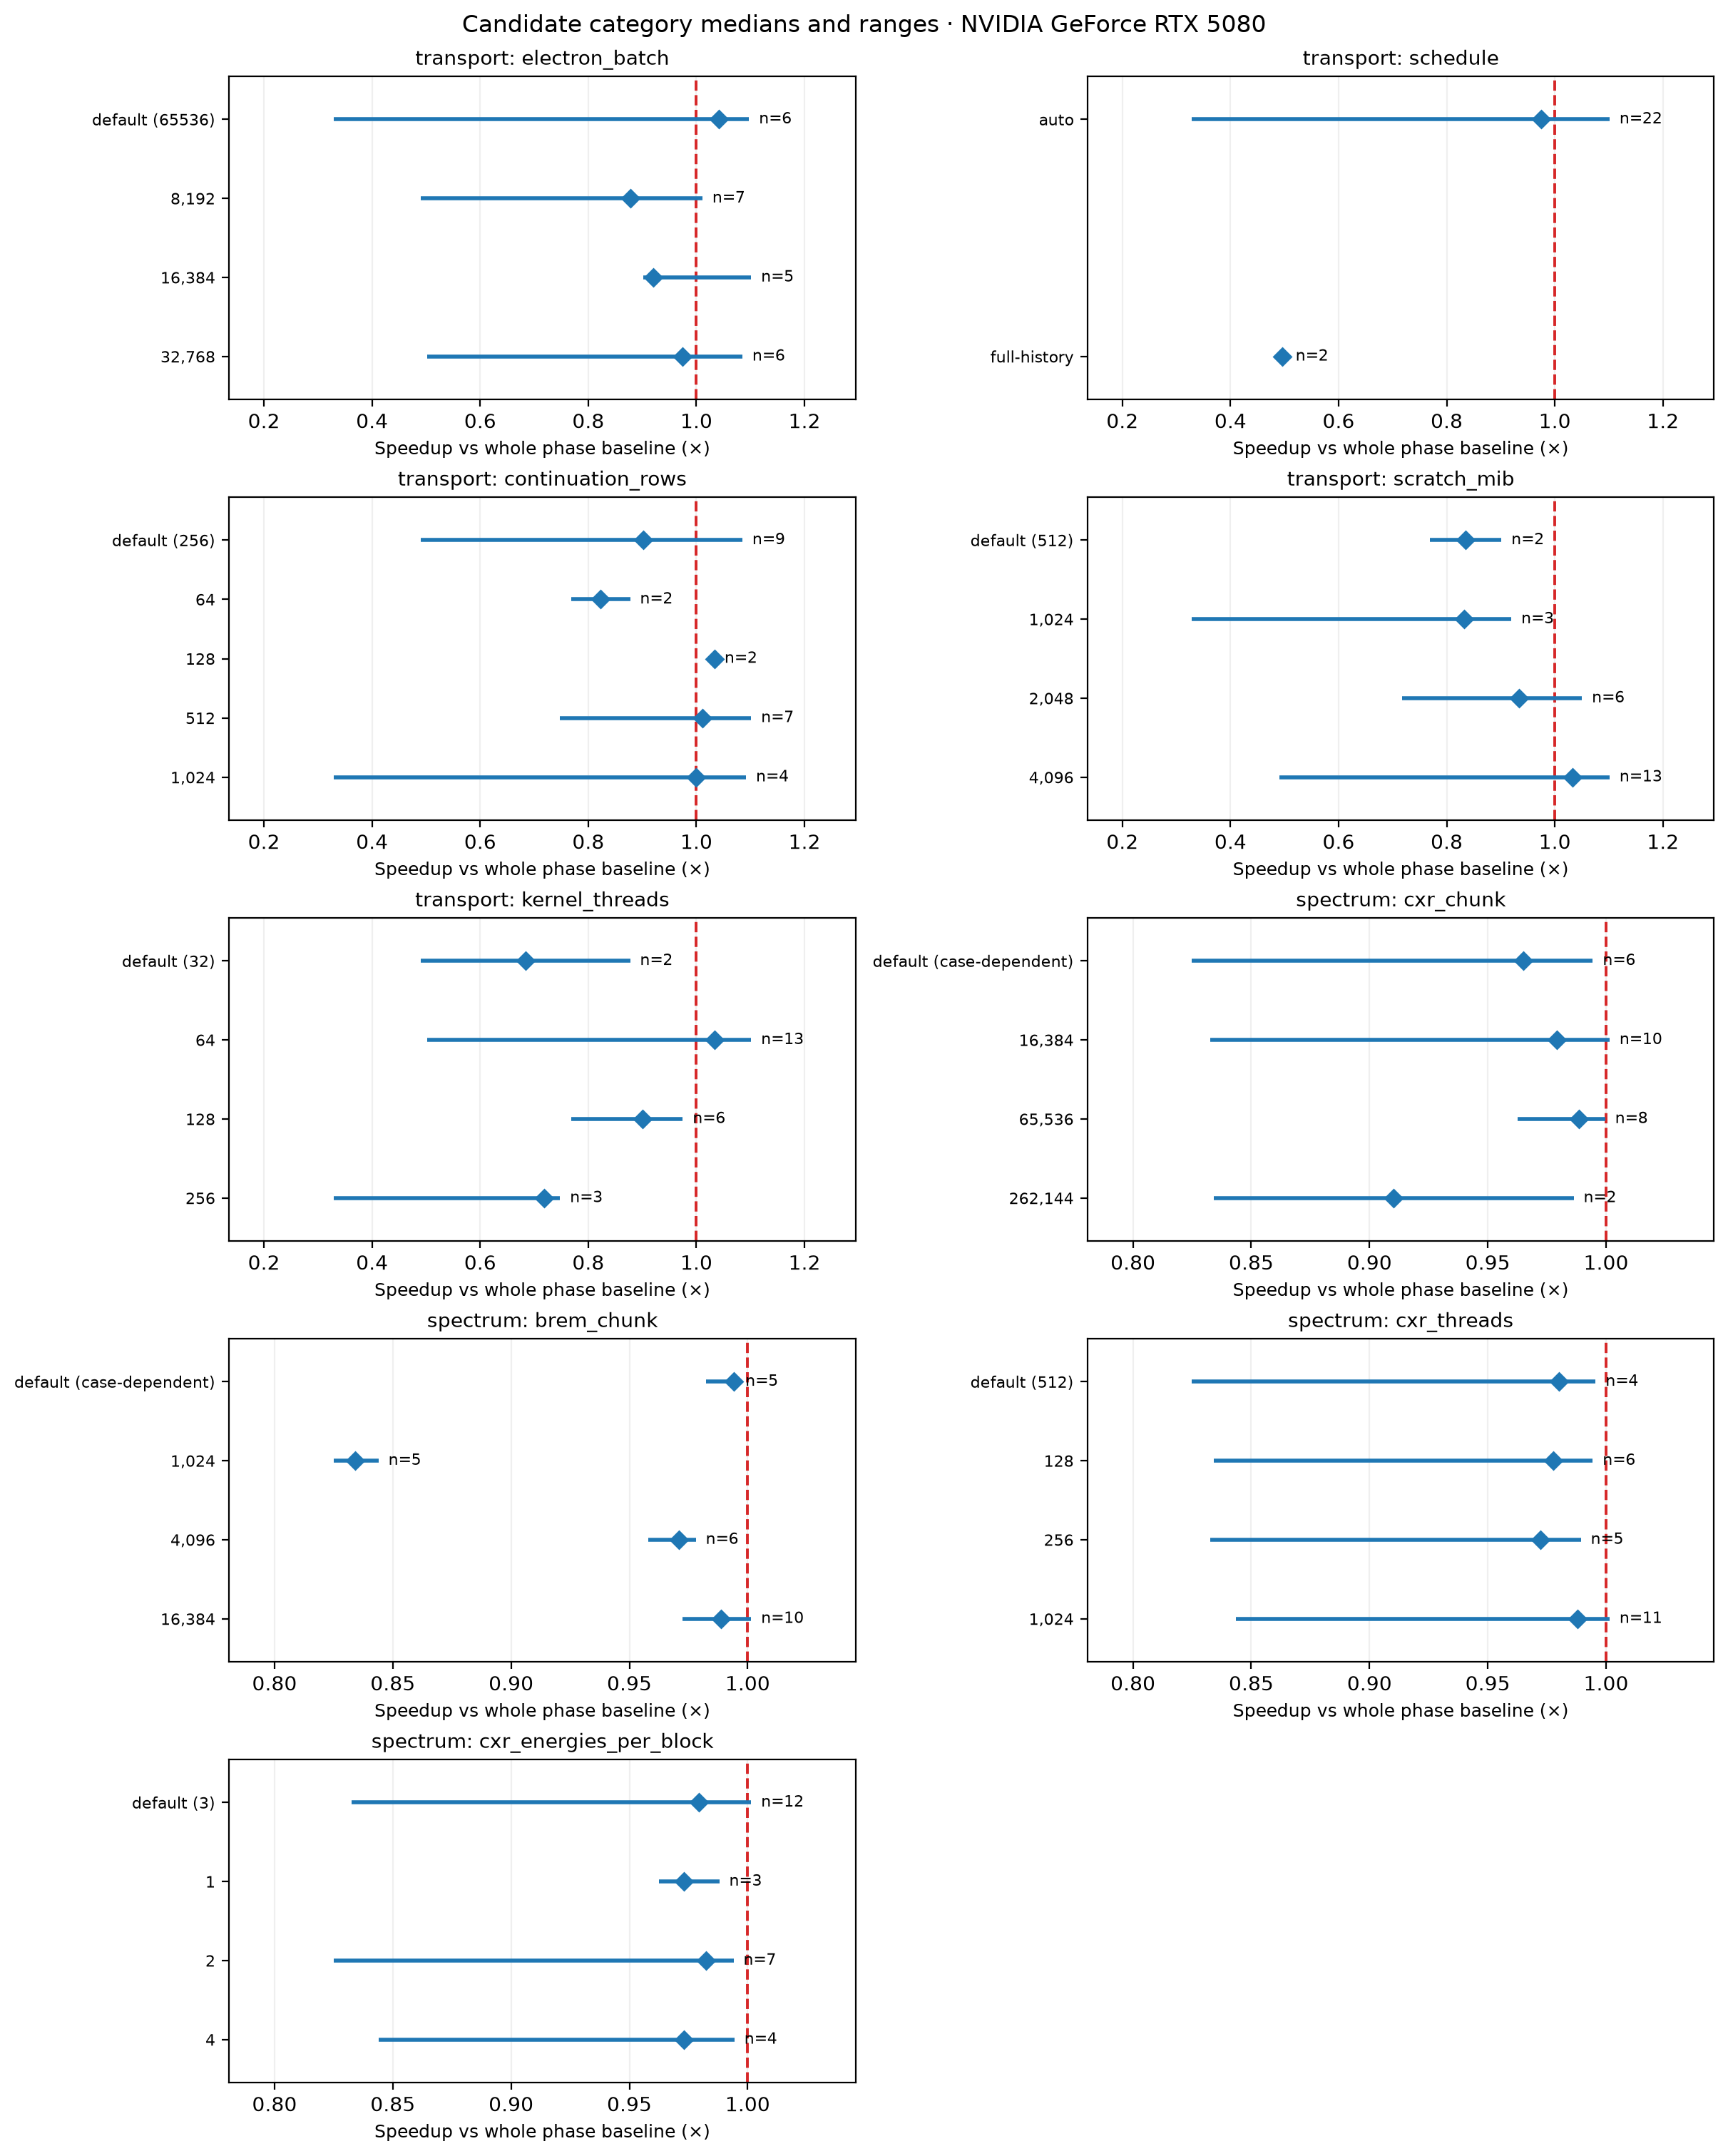

In [ ]:
_panels = [(_study, _name) for _study in tuning.phases for _name in space.dimensions(_study.phase)]
_cols = 2
fig_controls, _axes = plt.subplots(
    -(-len(_panels) // _cols),
    _cols,
    figsize=(12, 3.0 * -(-len(_panels) // _cols)),
    layout="constrained",
    squeeze=False,
)
for _ax, (_study, _name) in zip(_axes.flat, _panels, strict=False):
    _values = list(getattr(space, _name))
    _labels = [
        f"default ({defaults[_name]})"
        if value is None
        else f"{value:,}"
        if isinstance(value, int)
        else str(value)
        for value in _values
    ]
    _done = [
        trial
        for trial in _study.trials
        if trial.state == "complete" and trial.repeat_of is None and trial.median_s > 0
    ]
    _baseline_s = _study.baseline.median_s
    _ax.axvline(1.0, color="C3", ls="--", lw=1.4, label="Whole baseline = 1×")
    for _row, (_value, _label) in enumerate(zip(_values, _labels, strict=True)):
        _times = np.array(
            [
                trial.median_s
                for trial in _done
                if getattr(
                    trial.tuning.transport if _study.phase == "transport" else trial.tuning,
                    _name,
                )
                == _value
            ]
        )
        if not len(_times):
            _ax.text(1, _row, "not sampled", color="0.5", fontsize=8, va="center", ha="left")
            continue
        _speedups = _baseline_s / _times
        _median = float(np.median(_speedups))
        _ax.hlines(_row, _speedups.min(), _speedups.max(), color="C0", lw=2)
        _ax.plot(_median, _row, marker="D", color="C0", ms=6)
        _ax.annotate(
            f"n={len(_times)}",
            (_speedups.max(), _row),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
        )
    _ax.set_yticks(range(len(_labels)), _labels, fontsize=8)
    _ax.invert_yaxis()
    _ax.set_title(f"{_study.phase}: {_name}", fontsize=10)
    _ax.set_xlabel("Speedup vs whole phase baseline (×)", fontsize=9)
    _ax.grid(axis="x", alpha=0.2)
    _ax.margins(x=0.25, y=0.18)
for _ax in list(_axes.flat)[len(_panels) :]:
    _ax.set_visible(False)
fig_controls.suptitle(
    f"Candidate category medians and ranges · {tuning.environment.get('device', 'GPU')}",
    fontsize=12,
)
fig_controls  # noqa: B018

## Apply and check the joined winner

`tuning.best` joins the transport winner with the spectrum winner.
Applying it through ordinary `Numerics` must leave the spectrum unchanged
up to the summation-order differences that chunking and the reduction
launch can introduce.

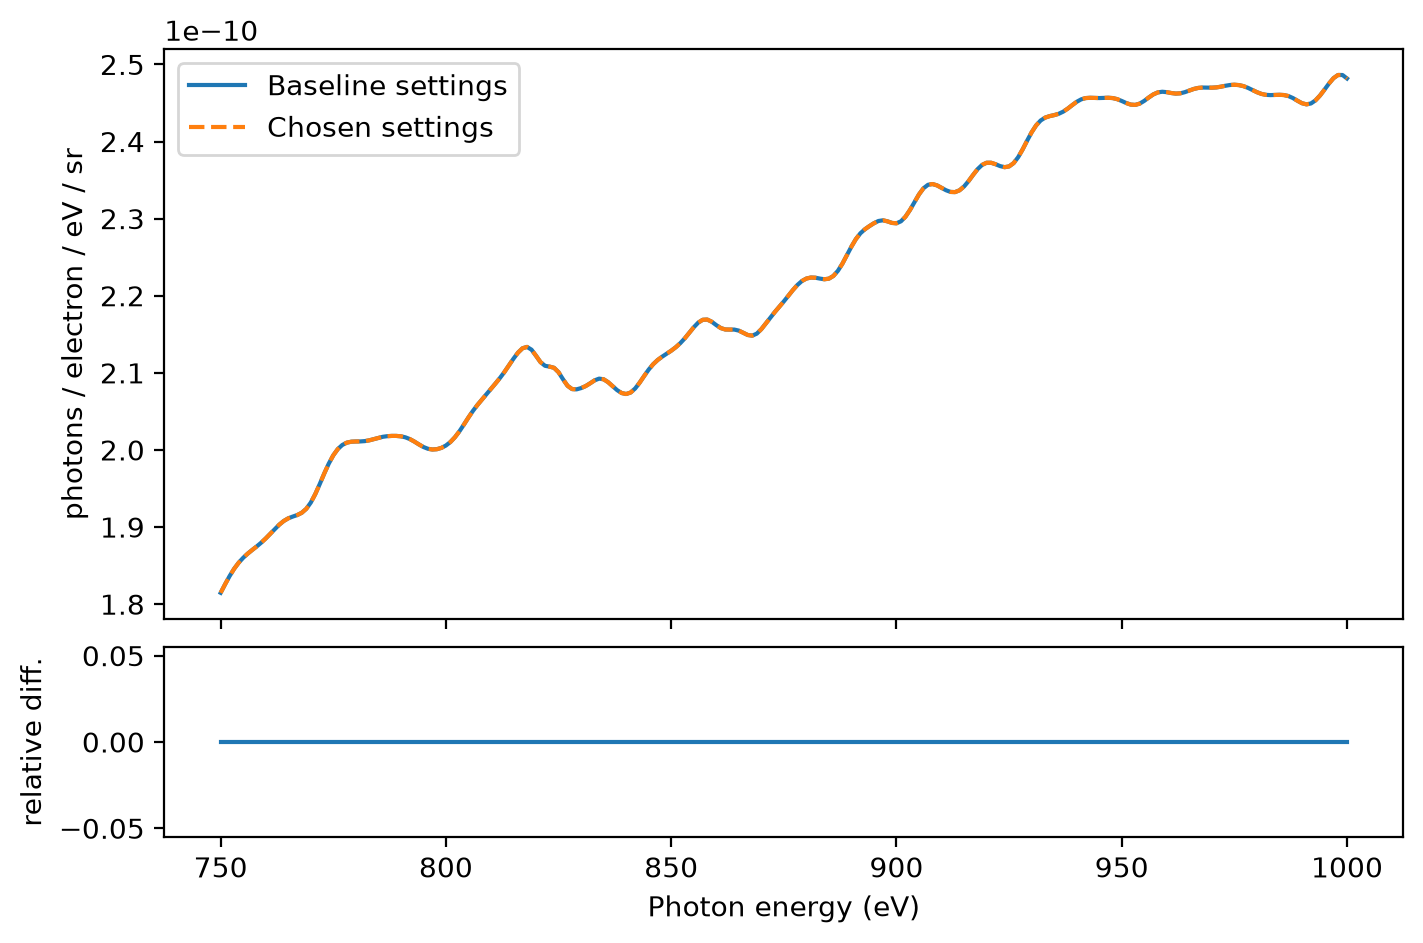

In [ ]:
with mo.status.progress_bar(total=2, title="Checking spectra after tuning") as _progress:
    baseline_result = pyrite.simulate(scene)
    _progress.update(subtitle="Original configuration")
    tuned_result = pyrite.simulate(scene, numerics=scene.numerics.with_kernel_tuning(tuning.best))
    _progress.update(subtitle="Joined transport + spectrum winners")
_energy = baseline_result.cxr.incoherent.photon_energy_eV
_base = baseline_result.cxr.incoherent.density
_tuned = tuned_result.cxr.incoherent.density
assert np.array_equal(_energy, tuned_result.cxr.incoherent.photon_energy_eV)
assert np.allclose(_tuned, _base, rtol=1e-4, atol=1e-12)
_floor = 1e-6 * np.abs(_base).max()
_relative = (_tuned - _base) / np.maximum(np.abs(_base), _floor)

fig_check, (_top, _bottom) = plt.subplots(
    2, 1, figsize=(7, 4.6), sharex=True, layout="constrained", height_ratios=(3, 1)
)
_top.plot(_energy, _base, label="Baseline settings")
_top.plot(_energy, _tuned, "--", label="Chosen settings")
_top.set(ylabel="photons / electron / eV / sr")
_top.legend()
_bottom.plot(_energy, _relative)
_bottom.set(xlabel="Photon energy (eV)", ylabel="relative diff.")
fig_check  # noqa: B018

In [ ]:
import json
from dataclasses import asdict

_record = {
    "gpu": gpu,
    "environment": tuning.environment,
    "best": asdict(tuning.best),
    "phases": [asdict(_study) for _study in tuning.phases],
}
mo.download(
    data=json.dumps(_record, indent=1, default=str).encode(),
    filename="pyrite-kernel-tuning.json",
    label="Download the tuning record (JSON)",
)

&lt;marimo-download data-initial-value=&#x27;null&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eDownload the tuning record (JSON)&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-data=&#x27;&amp;quot;...&amp;quot;&#x27; data-filename=&#x27;&amp;quot;pyrite-kernel-tuning.json&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-lazy=&#x27;false&#x27;&gt;&lt;/marimo-download&gt;

## What the numbers mean

Every candidate runs in one CUDA **worker process** that compiles kernels
and loads tables once and releases the device memory pool before each
candidate; `isolate="candidate"` restarts it per candidate instead, at a
large cost. A candidate gets one untimed warm-up and the chosen number of
synchronized timed runs of its phase. The fastest accepted candidate is
then re-timed in interleaved pairs with the baseline, and replaces it only
for at least a 2% confirmed gain (`min_speedup`). "Kept the baseline"
means the defaults were already as fast here, not that tuning failed.

A candidate is **rejected**, not timed, when its transport differs by a
single bit, its spectrum leaves the tolerance, or it needs the
out-of-memory chunk-halving retry. A large `scratch_mib` that does not fit
beside the tables is therefore reported, not silently slowed.

The transport timer includes trajectory setup and line-grid resolution;
the spectrum timer includes CXR, characteristic and bremsstrahlung
scoring. Neither isolates one kernel launch. The equality checks are a
tuning guard, not scientific validation. Winners are GPU-, driver- and
workload-specific: keep the downloaded record with its device, re-tune for
a production workload, and apply
`scene.numerics.with_kernel_tuning(tuning.best)` in a new process.

## Continue learning

The [CUDA execution tuning how-to](../../guides/batch-chunk-tuning.md) applies a
winner and covers the CLI and Molab runs; the
[execution and acceleration explanation](../../computation/execution-and-acceleration.md)
describes each control and its defaults. The
[experimental API reference](../../reference/python-api/experimental.md#cuda-execution-tuning)
lists `tune_kernels`, `KernelSearchSpace` and `TransportKernelTuning`.

{download}`Download canonical Marimo notebook <../19-tuning-cuda-execution.py>`